# Modèle TF-IDF : LinearSVC (notebooks/02_tfidf.ipynb)

Classification binaire des requêtes HTTP (1 = malveillante) avec des n-grammes de caractères (TF-IDF) et un LinearSVC.


In [ ]:
!pip install scikit-learn pandas pyarrow matplotlib joblib

## Choix du modèle

Critères, dans l'ordre : F1, taux de faux positifs (FPR), temps, simplicité.

| Modèle | F1 (CV) | FPR | Durée CV 5 plis |
|---|---|---|---|
| **LinearSVC** | 0,9837 | 1,24 % | 161 s |
| XGBoost | 0,9902 | 0,89 % | 662 s |
| RandomForest | 0,9683 | 7,25 % | 233 s |
| LogReg | 0,9667 | 2,85 % | 207 s |
| NaiveBayes | 0,8806 | 30,6 % | 151 s |

- LinearSVC atteint presque la qualité de XGBoost (F1 0,9837 contre 0,9902) pour environ 4 fois moins de temps (161 s contre 662 s). Sans réglage, il égale déjà la LogReg réglée (0,9833).
- XGBoost est un peu meilleur, mais son coût d'entraînement est trop élevé pour un jeu de 427 000 lignes avec réglage et recalcul du seuil.
- RandomForest et NaiveBayes ont un FPR trop haut pour un WAF.
- LinearSVC n'a pas de `predict_proba` : on l'enveloppe dans `CalibratedClassifierCV` pour obtenir des probabilités (nécessaires pour le seuil et pour l'API).

## 0. Imports et données (échantillon)

In [2]:
import sys
sys.path.append("..")

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (make_scorer, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve,
                             f1_score, precision_score, recall_score)

os.makedirs("../models", exist_ok=True)
os.makedirs("../rapport", exist_ok=True)

train = pd.read_parquet("../data/sample.parquet")
X_train, y_train = train["text"], train["label"].astype(int)
print(len(X_train), round(float(y_train.mean()), 3))

50000 0.682


## 1. Résultats de la comparaison

Validation croisée à 5 plis sur l'échantillon de 50 000 lignes. La durée comprend le TF-IDF refait à chaque pli. Baseline (« toujours malveillant ») : F1 0,811 mais FPR 1,0.

le F1 seul ne suffit pas (la baseline a déjà 0,811) ; le FPR mesure les vrais clients bloqués ; les n-grammes de caractères battent nettement les mots.

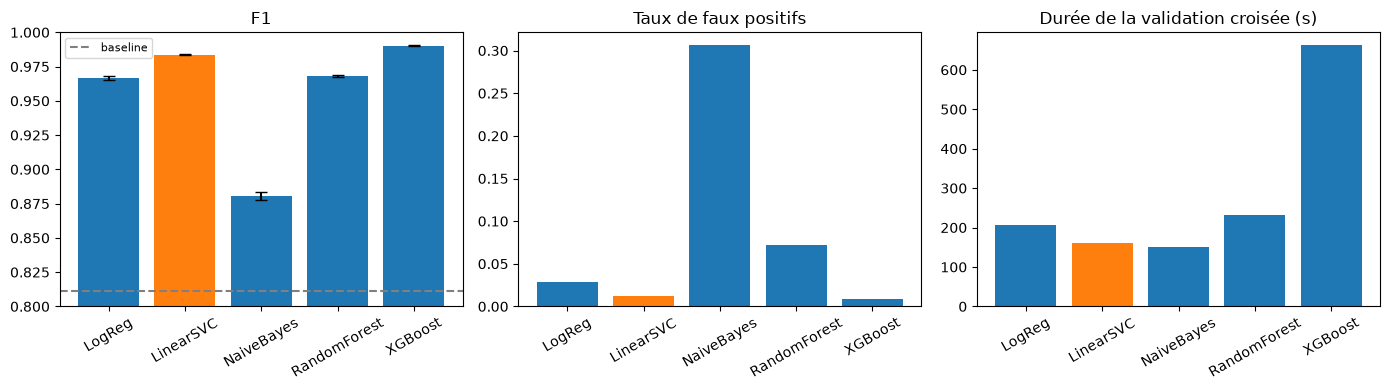

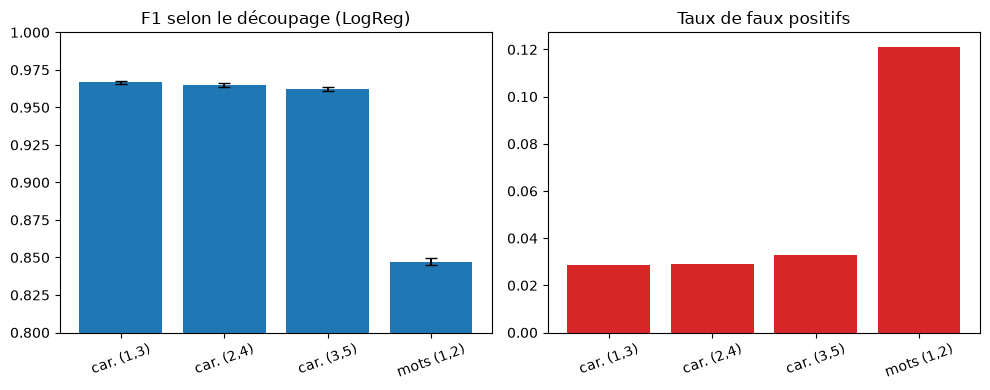

In [3]:
# Valeurs mesurées dans 02_tfidf.ipynb (pas de recalcul ici)
resultats = pd.DataFrame({
    "f1":    [0.9667, 0.9837, 0.8806, 0.9683, 0.9902],
    "f1_std":[0.0012, 0.0004, 0.0031, 0.0009, 0.0005],
    "fpr":   [0.0285, 0.0124, 0.3061, 0.0725, 0.0089],
    "duree": [207, 161, 151, 233, 662],
}, index=["LogReg", "LinearSVC", "NaiveBayes", "RandomForest", "XGBoost"])

ng = pd.DataFrame({
    "f1":    [0.9667, 0.9648, 0.9622, 0.8473],
    "f1_std":[0.0012, 0.0013, 0.0014, 0.0024],
    "fpr":   [0.0285, 0.0289, 0.0327, 0.1212],
}, index=["car. (1,3)", "car. (2,4)", "car. (3,5)", "mots (1,2)"])

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
couleurs = ["tab:orange" if m == "LinearSVC" else "tab:blue" for m in resultats.index]
ax[0].bar(resultats.index, resultats["f1"], yerr=resultats["f1_std"], capsize=4, color=couleurs)
ax[0].axhline(0.811, color="gray", ls="--", label="baseline")
ax[0].set_ylim(0.8, 1.0); ax[0].set_title("F1"); ax[0].legend(fontsize=8)
ax[1].bar(resultats.index, resultats["fpr"], color=couleurs)
ax[1].set_title("Taux de faux positifs")
ax[2].bar(resultats.index, resultats["duree"], color=couleurs)
ax[2].set_title("Durée de la validation croisée (s)")
for a in ax:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../rapport/fig_comparaison_modeles.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(ng.index, ng["f1"], yerr=ng["f1_std"], capsize=4, color="tab:blue")
ax[0].set_ylim(0.8, 1.0); ax[0].set_title("F1 selon le découpage (LogReg)")
ax[1].bar(ng.index, ng["fpr"], color="tab:red")
ax[1].set_title("Taux de faux positifs")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../rapport/fig_ngrammes.png", bbox_inches="tight", dpi=150)
plt.show()

## 2. Configuration commune

- StratifiedKFold garde la proportion 68/32 dans chaque pli ; mêmes plis pour tous les essais.
- Le FPR est la métrique clé d'un WAF : un faux positif = un vrai client bloqué.
- Le Pipeline refait le TF-IDF dans chaque pli (pas de fuite) et donne un seul fichier à déployer.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def fpr(y_true, y_pred):
    """Taux de faux positifs : part des requêtes légitimes bloquées à tort."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp / (fp + tn)

def make_pipe(clf, ngram_range=(1, 3), max_features=100_000):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=ngram_range,
                                  max_features=max_features, sublinear_tf=True)),
        ("clf", clf),
    ])

## 3. Réglage du LinearSVC (GridSearchCV, sur l'échantillon)

On règle la taille des n-grammes et `C` (force de régularisation : plus grand = moins de régularisation). Grille volontairement petite (6 combinaisons × 5 plis), avec `n_jobs=2` pour limiter la mémoire.

GridSearchCV teste toutes les combinaisons d'hyperparamètre en validation croisée et garde la meilleure.

In [5]:
pipe = make_pipe(LinearSVC(class_weight="balanced"))
grid = {
    "tfidf__ngram_range": [(1, 3), (2, 4)],
    "clf__C": [0.1, 1, 10],
}
gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=2, verbose=1)
gs.fit(X_train, y_train)
print(gs.best_params_, round(gs.best_score_, 4))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
{'clf__C': 10, 'tfidf__ngram_range': (2, 4)} 0.9909


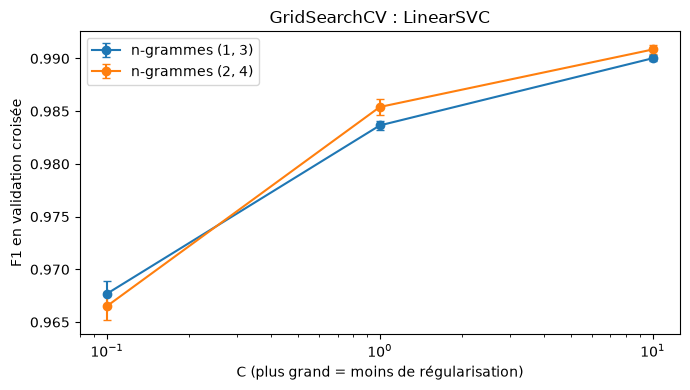

In [6]:
res = pd.DataFrame(gs.cv_results_)
res["ngram"] = res["param_tfidf__ngram_range"].astype(str)
res["C"] = res["param_clf__C"].astype(float)

fig, ax = plt.subplots(figsize=(7, 4))
for ngr, g in res.groupby("ngram"):
    g = g.sort_values("C")
    ax.errorbar(g["C"], g["mean_test_score"], yerr=g["std_test_score"],
                marker="o", capsize=3, label=f"n-grammes {ngr}")
ax.set_xscale("log")
ax.set_xlabel("C (plus grand = moins de régularisation)")
ax.set_ylabel("F1 en validation croisée")
ax.set_title("GridSearchCV : LinearSVC")
ax.legend()
plt.tight_layout()
plt.savefig("../rapport/fig_gridsearch.png", bbox_inches="tight", dpi=150)
plt.show()

## 4. Modèle final et choix du seuil

**Calibration** : le modèle final est TF-IDF puis CalibratedClassifierCV(LinearSVC), ce qui donne un predict_proba utilisable par l'API.

**Seuil** : par défaut on bloque si proba ≥ 0,5. Pour un WAF on préfère limiter les faux positifs : on choisit le seuil qui garde au plus 1 % de légitimes bloquées. Pour aller vite sur le train complet, il est calculé sur un seul découpage du train (80 % pour entraîner, 20 % pour choisir le seuil), sans toucher au test.

Cette cellule charge le train complet et entraîne un modèle.

In [ ]:
train_full = pd.read_parquet("../data/train.parquet")
test = pd.read_parquet("../data/test.parquet")
X_train, y_train = train_full["text"], train_full["label"].astype(int)
X_test, y_test = test["text"], test["label"].astype(int)
print(len(X_train), len(X_test))

bp = gs.best_params_
def make_final():
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=bp["tfidf__ngram_range"],
                                  max_features=100_000, sublinear_tf=True)),
        ("clf", CalibratedClassifierCV(LinearSVC(C=bp["clf__C"], class_weight="balanced"), cv=3)),
    ])

# Seuil : 80 % du train pour entraîner, 20 % pour choisir
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              stratify=y_train, random_state=42)
modele_seuil = make_final().fit(X_fit, y_fit)
proba_val = modele_seuil.predict_proba(X_val)[:, 1]

fprs, tprs, seuils = roc_curve(y_val, proba_val)
cible = 0.01                                   # au plus 1 % de légitimes bloquées
j = np.where(fprs <= cible)[0][-1]
SEUIL = float(seuils[j])
print(f"Seuil = {SEUIL:.3f} -> FPR = {fprs[j]:.4f}, détection = {tprs[j]:.4f}")

427555 106889


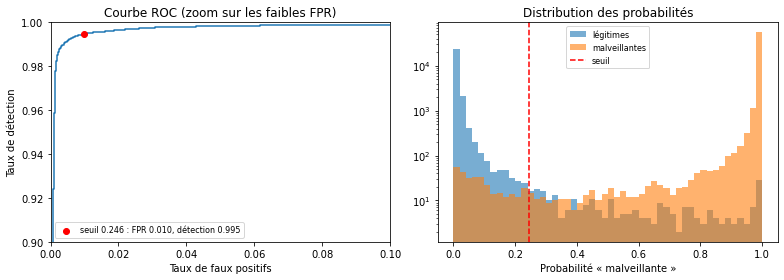

In [ ]:
yv = np.asarray(y_val)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fprs, tprs)
ax[0].scatter([fprs[j]], [tprs[j]], color="red", zorder=3,
              label=f"seuil {SEUIL:.3f} : FPR {fprs[j]:.3f}, détection {tprs[j]:.3f}")
ax[0].set_xlim(0, 0.1); ax[0].set_ylim(0.9, 1.0)
ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de détection")
ax[0].set_title("Courbe ROC (zoom sur les faibles FPR)"); ax[0].legend(fontsize=8)
ax[1].hist(proba_val[yv == 0], bins=50, alpha=0.6, label="légitimes")
ax[1].hist(proba_val[yv == 1], bins=50, alpha=0.6, label="malveillantes")
ax[1].axvline(SEUIL, color="red", ls="--", label="seuil")
ax[1].set_yscale("log")
ax[1].set_xlabel("Probabilité « malveillante »"); ax[1].set_title("Distribution des probabilités")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../rapport/fig_seuil.png", bbox_inches="tight", dpi=150)
plt.show()

## 5. Évaluation finale sur le test

On entraîne le modèle final sur tout le train, puis on évalue sur le test. On regarde aussi le rappel par type d'attaque pour vérifier que le modèle ne détecte pas que les injections SQL.

/Users/matheogastel/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py:1206: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


              precision    recall  f1-score   support

    légitime     0.9891    0.9892    0.9892     34075
malveillante     0.9950    0.9949    0.9949     72814

    accuracy                         0.9931    106889
   macro avg     0.9920    0.9921    0.9921    106889
weighted avg     0.9931    0.9931    0.9931    106889

FPR test : 0.0108


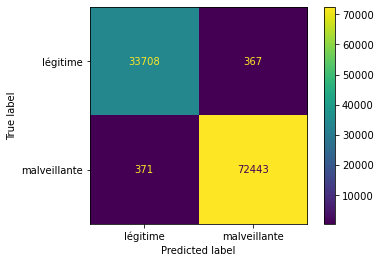

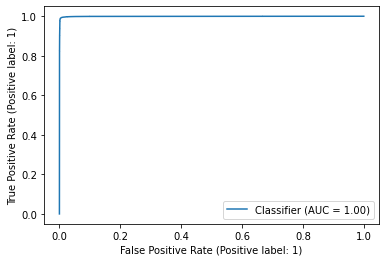

F1           0.9949
précision    0.9950
rappel       0.9949
FPR          0.0108
dtype: float64

In [24]:
final = make_final().fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
y_pred = (proba >= SEUIL).astype(int)

print(classification_report(y_test, y_pred, target_names=["légitime", "malveillante"], digits=4))
print("FPR test :", round(fpr(y_test, y_pred), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["légitime", "malveillante"])
plt.savefig("../rapport/fig_confusion.png", bbox_inches="tight"); plt.show()

RocCurveDisplay.from_predictions(y_test, proba)
plt.savefig("../rapport/fig_roc.png", bbox_inches="tight"); plt.show()

pd.Series({
    "F1": f1_score(y_test, y_pred),
    "précision": precision_score(y_test, y_pred),
    "rappel": recall_score(y_test, y_pred),
    "FPR": fpr(y_test, y_pred),
}).round(4)

In [25]:
# Rappel par type d'attaque
attack_cols = [c for c in test.columns if c[0].isdigit() and not c.startswith("000")]
for c in attack_cols:
    m = test[c] == 1
    if m.sum() >= 20:
        print(f"{c:<42} {m.sum():>6} requêtes  rappel = {y_pred[m.values].mean():.3f}")

272 - Protocol Manipulation                  1510 requêtes  rappel = 0.865
242 - Code Injection                         3169 requêtes  rappel = 1.000
88 - OS Command Injection                    1459 requêtes  rappel = 0.985
126 - Path Traversal                         3815 requêtes  rappel = 0.993
66 - SQL Injection                          49149 requêtes  rappel = 0.998
16 - Dictionary-based Password Attack         337 requêtes  rappel = 1.000
310 - Scanning for Vulnerable Software        489 requêtes  rappel = 0.998
153 - Input Data Manipulation                 463 requêtes  rappel = 0.998
274 - HTTP Verb Tampering                    1003 requêtes  rappel = 0.996
194 - Fake the Source of Data                9166 requêtes  rappel = 0.997
34 - HTTP Response Splitting                 3942 requêtes  rappel = 1.000
33 - HTTP Request Smuggling                   204 requêtes  rappel = 1.000


## 6. Latence

Une requête à la fois, comme dans l'API (le WAF est sur le chemin de chaque requête).

In [26]:
echantillon = X_test.sample(300, random_state=42).tolist()
t0 = time.perf_counter()
for t in echantillon:
    final.predict_proba([t])
lat = (time.perf_counter() - t0) / len(echantillon) * 1000
print(f"Latence moyenne : {lat:.2f} ms par requête")

Latence moyenne : 2.03 ms par requête


## 7. Interprétation

On regarde les n-grammes qui pèsent le plus dans le LinearSVC réglé (entraîné sur l'échantillon, mêmes hyperparamètres que le modèle final).

Si on retrouve `uni`, `sel`, `../`, `<sc`, le modèle a appris de vrais motifs d'attaque.
Le texte contient aussi les headers (user-agent, referer…) ; vérifier que les n-grammes lourds ne sont pas des artefacts du dataset.

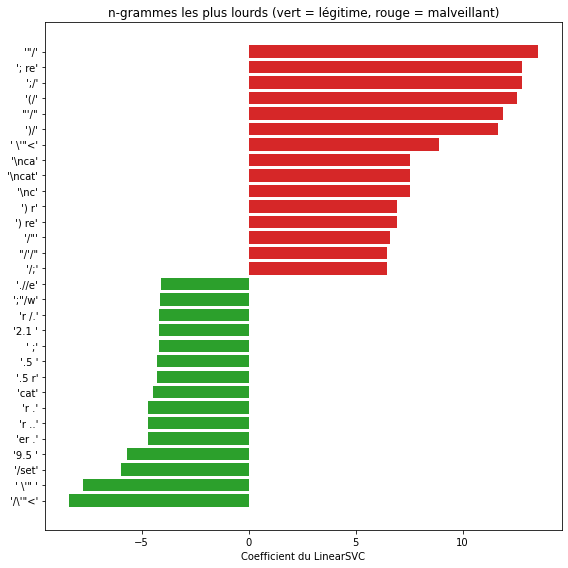

In [27]:
interp = gs.best_estimator_
noms = interp.named_steps["tfidf"].get_feature_names_out()
coefs = pd.Series(interp.named_steps["clf"].coef_[0], index=noms).sort_values()
sel = pd.concat([coefs.head(15), coefs.tail(15)])

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([repr(n) for n in sel.index], sel.values, color=["tab:green"] * 15 + ["tab:red"] * 15)
ax.set_title("n-grammes les plus lourds (vert = légitime, rouge = malveillant)")
ax.set_xlabel("Coefficient du LinearSVC")
plt.tight_layout()
plt.savefig("../rapport/fig_coefficients.png", bbox_inches="tight", dpi=150)
plt.show()

## 8. Export

Le modèle exporté est le pipeline complet (TF-IDF + LinearSVC calibré) : l'API appelle predict_proba sur le texte et bloque si la probabilité dépasse le seuil de seuil.txt.

> Pour l'API : le texte doit être construit exactement comme dans 01_donnees.ipynb (build_text_df : Host/Referer normalisés, URL décodée deux fois, minuscules).

In [28]:
joblib.dump(final, "../models/waf.joblib")
with open("../models/seuil.txt", "w") as f:
    f.write(str(SEUIL))

# Test de rechargement : mêmes probabilités avant / après
m = joblib.load("../models/waf.joblib")
check = X_test.iloc[:500]
assert np.allclose(m.predict_proba(check)[:, 1], final.predict_proba(check)[:, 1])
print("Rechargement OK, seuil =", SEUIL)

for lab in (0, 1):
    for t in X_test[y_test == lab].sample(2, random_state=42):
        print(f"label={lab}  proba={m.predict_proba([t])[0, 1]:.3f}  {t[:90]}")

Rechargement OK, seuil = 0.24576028783698792
label=0  proba=0.985  request_http_method post request_http_request /blog//../../../../../../../../../../../../.
label=0  proba=0.005  request_http_method get request_http_request /blog/index.php||cat+/etc/passwd/et-vel-qui-e
label=1  proba=0.999  request_http_method get request_http_request /blog&&sleep+15/wp-content/plugins/user-regis
label=1  proba=1.000  request_http_method get request_http_request /blog/index.php/2020/03/27/qui-ratione-maxime
